In [2]:
# Basic libraries for text processing, data handling, and plotting
import re
import nltk
from nltk.corpus import stopwords
import pandas as pd
import numpy as np
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import seaborn as sns

# Gensim libraries for LDA and TF-IDF
from gensim.corpora import Dictionary
from gensim.models import LdaModel, TfidfModel

# WordCloud for visualization
from wordcloud import WordCloud

# BERTopic and its dependencies for advanced topic modeling
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from hdbscan import HDBSCAN
from umap import UMAP

# Ensure NLTK data is downloaded
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

True

In [3]:
# --- Data Loading and Parsing ---
# Read the text file and split it into separate documents.

with open("../data/tourism.txt", "r", encoding="utf-8") as f:
    content = f.read()

content = content.lstrip("\ufeff")
raw_docs = content.split("===")

docs = []
for block in raw_docs:
    block = block.strip()
    if not block:
        continue

    lines = block.splitlines()

    # Remove the first line if it contains the site label
    if lines and lines[0].lower().startswith("site"):
        lines = lines[1:]

    # Join the remaining lines to form a single document text
    text = " ".join(line.strip() for line in lines if line.strip())
    if text:
        docs.append(text)

print(f"Documents found in Tourism: {len(docs)}")

Documents found in Tourism: 10


In [4]:
# --- Step 1: Using TF-IDF to Identify Custom Stopwords ---
# TF-IDF (Term Frequency-Inverse Document Frequency) is a statistical measure that
# evaluates the importance of a word within a document relative to a collection of
# documents (a corpus). It works in two parts:
# - Term Frequency (TF): How often a word appears in a single document.
# - Inverse Document Frequency (IDF): A measure of how rare or common a word is
#   across all documents. Common words will have a low IDF score, while rare,
#   specific words will have a high score.
#
# The TF-IDF score is the product of these two values. It highlights words that are
# frequent in one document but not in others, making it perfect for identifying
# terms that are characteristic of a specific document.
#
#
# The goal is to programmatically find words that are highly specific to a single
# document (like company names). These words can distort topic models like LDA,
# which look for themes shared across the corpus.
#
# TF-IDF is perfect for this. By finding the word with the highest TF-IDF score
# in each document, we can identify these characteristic terms and treat them as
# custom stopwords.

# First, define standard English stopwords.
stop_words = set(stopwords.words('english'))

# Create a preprocessing function that only removes standard stopwords.
def preprocess_for_stopword_identification(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s\-]", " ", text)
    tokens = nltk.word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]
    return tokens

# Apply this preprocessing to all documents
texts_for_tfidf = [preprocess_for_stopword_identification(doc) for doc in docs]

# Create Gensim Dictionary and Corpus
dictionary_tfidf = Dictionary(texts_for_tfidf)
corpus_tfidf = [dictionary_tfidf.doc2bow(text) for text in texts_for_tfidf]

# Train the TF-IDF model
tfidf_model = TfidfModel(corpus_tfidf, id2word=dictionary_tfidf, normalize=True)
tfidf_corpus = [tfidf_model[bow] for bow in corpus_tfidf]

# Helper function to get top terms
def top_tfidf_terms(tfidf_doc, topn=10):
    top = sorted(tfidf_doc, key=lambda x: x[1], reverse=True)[:topn]
    return [(dictionary_tfidf[t_id], w) for t_id, w in top]

# Show top 5 TF-IDF terms for each document
print("Top 5 TF-IDF terms per document in Tourism:")
for i, tfdoc in enumerate(tfidf_corpus, start=1):
    tops = top_tfidf_terms(tfdoc, topn=5)
    tops_str = ", ".join(f"{term} ({w:.3f})" for term, w in tops)
    print(f"Doc {i}: {tops_str}")

Top 5 TF-IDF terms per document in Tourism:
Doc 1: traffic (0.349), flemish (0.314), measurements (0.261), party (0.150), vsds (0.150)
Doc 2: datahub (0.534), tirol (0.534), engineering (0.235), value-based (0.213), tyrol (0.171)
Doc 3: dates (0.550), tourism (0.363), engagement (0.205), dissemination (0.157), communication (0.151)
Doc 4: deploytour (0.426), tourism (0.257), fair (0.149), ethical (0.146), requires (0.128)
Doc 5: eona (0.700), tourism (0.171), travel (0.160), transport (0.160), assistant (0.131)
Doc 6: sscc (0.236), deployment (0.207), sscc-dep (0.207), phase (0.186), blueprint (0.186)
Doc 7: tidy-city (0.546), urban (0.254), vehicles (0.243), images (0.212), city (0.191)
Doc 8: tourilab (0.799), tourism (0.200), fiware (0.139), fuerteventura (0.133), lab (0.133)
Doc 9: truzzt (0.430), competence (0.354), traceability (0.202), contribution (0.185), interfaces (0.177)
Doc 10: uitwisselingsplatform (0.302), cultural (0.295), valuable (0.264), leisure (0.158), individual (

In [5]:
# --- Extract top terms as custom stopwords ---
# Use-case names, acronyms and place names with the highest TF-IDF scores above.
custom_stops = {"flemish", "datahub", "tirol", "tyrol", "datahubtirol", "dates", "deploytour", "eona", "sscc-dep", "sscc", "tidy-city", "tourilab", "fiware", "fuerteventura", "truzzt", "uitwisselingsplatform"}


Top 25 terms by mean TF-IDF across the corpus for Tourism:
tourilab: 0.799
eona: 0.700
dates: 0.550
tidy-city: 0.546
datahub: 0.534
tirol: 0.534
truzzt: 0.430
competence: 0.354
uitwisselingsplatform: 0.302
deploytour: 0.244
vehicles: 0.243
sscc: 0.236
engineering: 0.235
value-based: 0.213
flemish: 0.210
deployment: 0.207
sscc-dep: 0.207
tourism: 0.205
traceability: 0.202
traffic: 0.185
phases: 0.177
interfaces: 0.177
tyrol: 0.171
dissemination: 0.157
occurrences: 0.152

Word Cloud based on Mean TF-IDF scores for Tourism:


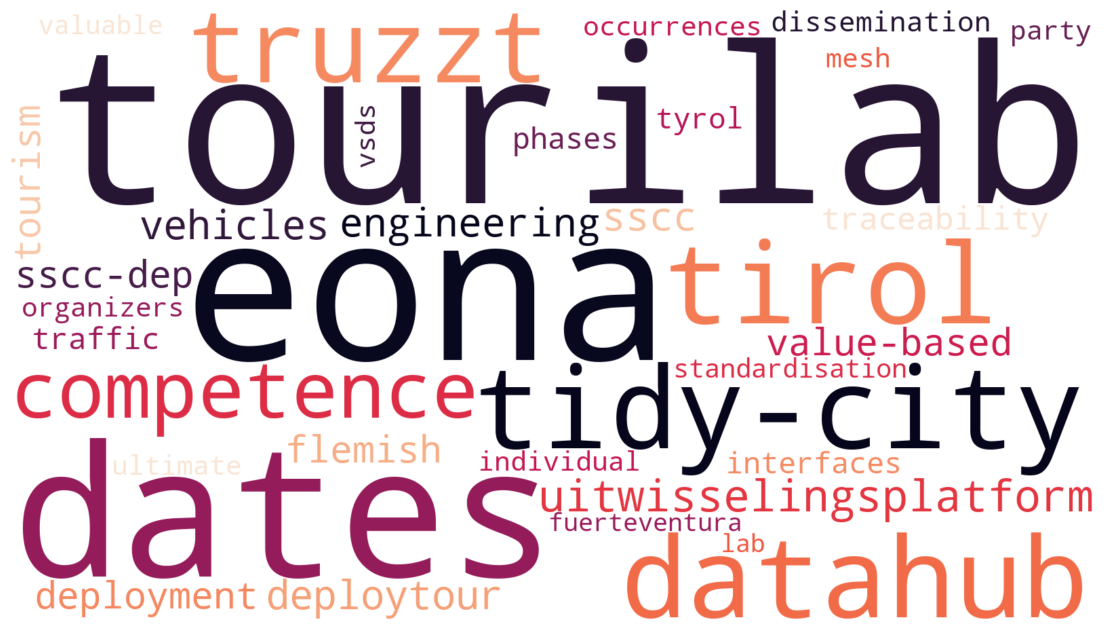

In [6]:
# --- Step 2: Mean TF-IDF and Word Cloud for Exploratory Analysis ---
# Now we calculate the average TF-IDF score for each word across all documents.
# This helps identify words that are generally important and distinctive, providing a
# more nuanced overview than raw frequency. The resulting Word Cloud will highlight
# these key terms.

sum_w = defaultdict(float)
count_w = defaultdict(int)
for tfdoc in tfidf_corpus:
    for t_id, w in tfdoc:
        sum_w[t_id] += w
        count_w[t_id] += 1

mean_tfidf = {dictionary_tfidf[t_id]: (sum_w[t_id] / count_w[t_id]) for t_id in sum_w}

# Sort the dictionary items by score to get the top terms for printing
sorted_mean_tfidf = sorted(mean_tfidf.items(), key=lambda item: item[1], reverse=True)

print("Top 25 terms by mean TF-IDF across the corpus for Tourism:")
for term, mw in sorted_mean_tfidf[:25]:
    print(f"{term}: {mw:.3f}")
    
# Generate Word Cloud from Mean TF-IDF scores
wc_tfidf = WordCloud(
    width=1600, height=900, background_color="white",
    prefer_horizontal=0.9, collocations=False, colormap='rocket', max_words=35, 
).generate_from_frequencies(mean_tfidf)

print("\nWord Cloud based on Mean TF-IDF scores for Tourism:")
plt.figure(figsize=(14, 8))
plt.imshow(wc_tfidf, interpolation="bilinear")
plt.axis("off")
plt.show()

In [7]:
all_tokens = [t for doc_tokens in texts_for_tfidf for t in doc_tokens]
freqs = Counter(all_tokens)

print("Token statistics for Tourism:")
print(f"Total tokens: {len(all_tokens)}")
print(f"Unique tokens: {len(freqs)}")

Token statistics for Tourism:
Total tokens: 9531
Unique tokens: 2412


In [8]:
# --- Define the final preprocessing function for LDA and BERTopic ---
# This function will be used to clean the text before feeding it to the models.
# It removes standard English stopwords as well as the custom stopwords identified earlier.

def preprocess_for_models(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s\-]", " ", text)
    tokens = nltk.word_tokenize(text)
    tokens = [
        t for t in tokens
        if t not in stop_words and len(t) > 2 and t not in custom_stops 
    ]
    return tokens

# Apply the final preprocessing to all documents
texts_processed_final = [preprocess_for_models(doc) for doc in docs]

Calculating Log Perplexity for different values of k...
k=2 -> log_perplexity=-7.1972
k=3 -> log_perplexity=-7.1617
k=4 -> log_perplexity=-7.1932
k=5 -> log_perplexity=-7.2735
k=6 -> log_perplexity=-7.2723
k=7 -> log_perplexity=-7.2672


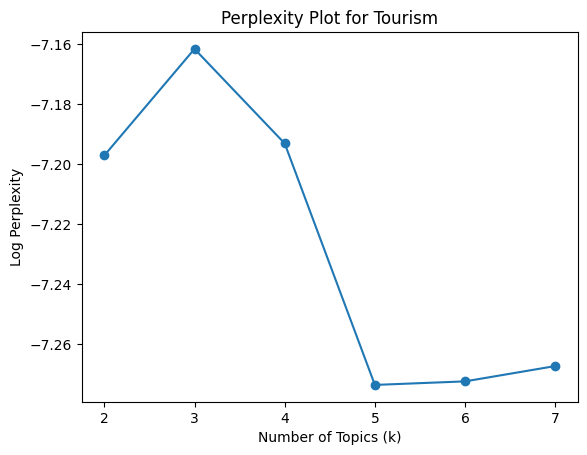

In [9]:
# --- Step 3: LDA (Latent Dirichlet Allocation) Model ---
# LDA is a "bag-of-words" topic model. We use the text cleaned with both standard
# and our dynamically identified custom stopwords to focus on broad, shared themes.

# Create the dictionary and corpus for the LDA model using the preprocessed text
dictionary_lda = Dictionary(texts_processed_final)
corpus_lda = [dictionary_lda.doc2bow(text) for text in texts_processed_final]

# --- Finding the Optimal Number of Topics (k) for LDA ---
# We calculate the perplexity score for different numbers of topics (k).
# A lower perplexity score generally indicates a better model. We look for an
# "elbow point" in the plot where the perplexity score stops improving significantly.
min_topics = 2
max_topics = 7
topic_range = range(min_topics, max_topics + 1)
perplexities = {}
models = {}

print("Calculating Log Perplexity for different values of k...")
for k in topic_range:
    lda = LdaModel(
        corpus=corpus_lda, id2word=dictionary_lda, num_topics=k,
        random_state=42, passes=15, alpha='auto',
    )
    models[k] = lda
    lp = lda.log_perplexity(corpus_lda)
    perplexities[k] = lp
    print(f"k={k} -> log_perplexity={lp:.4f}")

# Plotting the results to find the "elbow point"
plt.plot(list(perplexities.keys()), list(perplexities.values()), marker="o")
plt.xlabel("Number of Topics (k)")
plt.ylabel("Log Perplexity")
plt.title("Perplexity Plot for Tourism")
plt.show()

Topics for k=3 (with probabilities) in Tourism:
Topic 0 - 60% of documents
Topic 0: data (5.08%), tourism (1.58%), european (1.18%), space (1.09%), governance (0.74%), digital (0.65%), innovation (0.58%)
Topic 1 - 30% of documents
Topic 1: data (3.57%), digital (1.10%), systems (0.60%), core (0.60%), trust (0.57%), exchange (0.54%), secure (0.54%)
Topic 2 - 10% of documents
Topic 2: urban (1.09%), data (1.02%), project (0.76%), trust (0.69%), access (0.69%), images (0.69%), city (0.62%)

Main Topic per Document in Tourism:
Document 1: Topic 0 (p=99.72%)
Document 2: Topic 1 (p=99.78%)
Document 3: Topic 0 (p=99.88%)
Document 4: Topic 0 (p=99.89%)
Document 5: Topic 0 (p=99.74%)
Document 6: Topic 0 (p=99.90%)
Document 7: Topic 2 (p=99.75%)
Document 8: Topic 0 (p=99.69%)
Document 9: Topic 1 (p=99.87%)
Document 10: Topic 1 (p=99.50%)


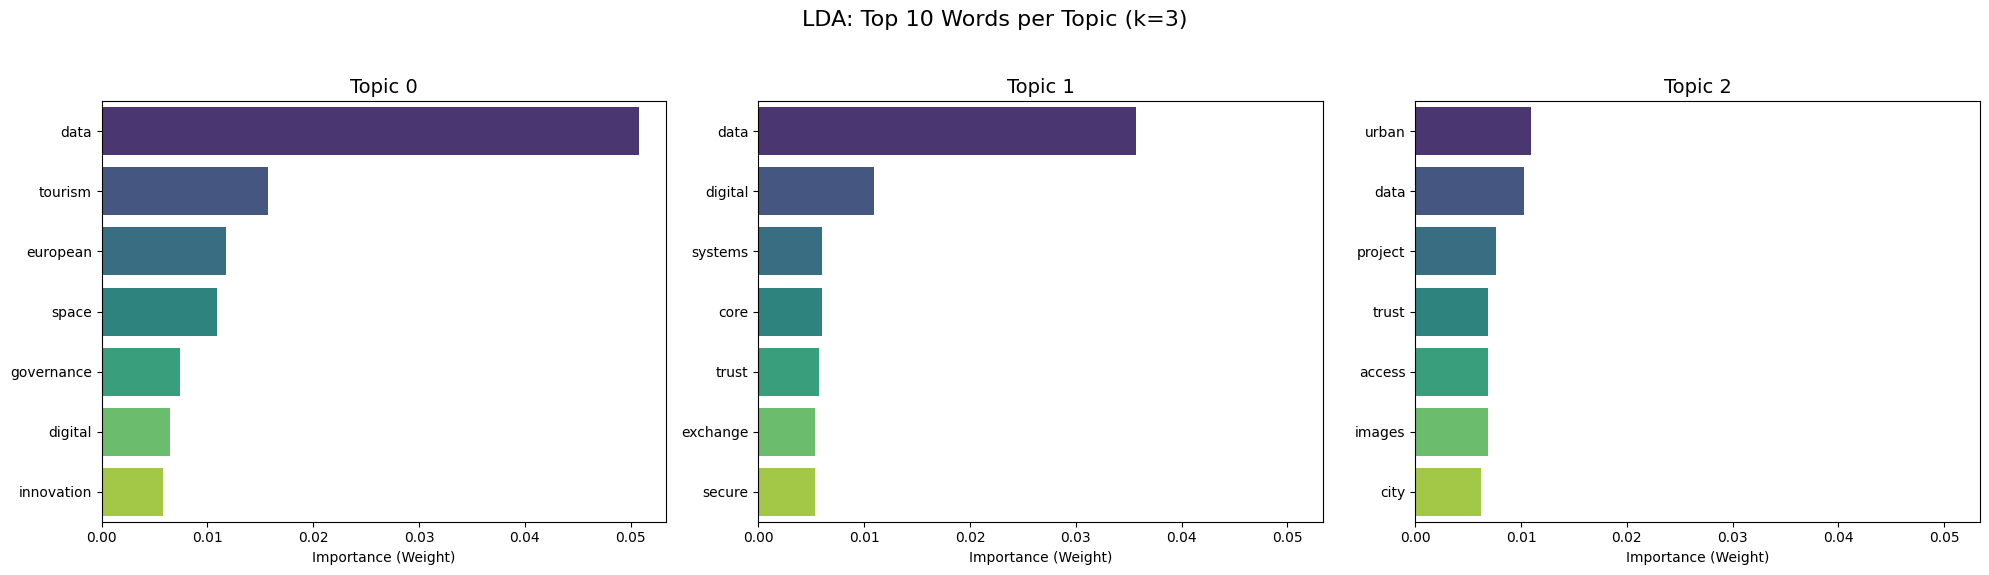

In [10]:
# --- Analyzing the Best LDA Model ---
best_k = 3
lda_best = models[best_k]

# Re-number topics by prevalence: Topic 0 = dominant topic in most documents
dominant = [max(lda_best.get_document_topics(bow), key=lambda x: x[1])[0] for bow in corpus_lda]
order = sorted(range(best_k), key=lambda t: -dominant.count(t))
new_id = {old: new for new, old in enumerate(order)}

print(f"Topics for k={best_k} (with probabilities) in Tourism:")
for old in order:
    i, topic = new_id[old], lda_best.show_topic(old, topn=7)
    share = dominant.count(old) / len(dominant)
    print(f"Topic {i} - {share:.0%} of documents")
    words_with_prob = ", ".join([f"{w} ({p*100:.2f}%)" for w, p in topic])
    print(f"Topic {i}: {words_with_prob}")

print("\nMain Topic per Document in Tourism:")
for idx, bow in enumerate(corpus_lda):
    doc_topics = lda_best.get_document_topics(bow)
    main_topic = sorted(doc_topics, key=lambda x: x[1], reverse=True)[0]
    print(f"Document {idx+1}: Topic {new_id[main_topic[0]]} (p={main_topic[1]*100:.2f}%)")

# --- Top Words Bar Charts for LDA ---
# Extract words and their weights for the chosen number of topics (best_k)
topics_data = [(new_id[old], lda_best.show_topic(old, topn=7)) for old in order]

# Set up the subplots grid
fig, axes = plt.subplots(1, best_k, figsize=(20, 6), sharex=True)
fig.suptitle(f'LDA: Top 10 Words per Topic (k={best_k})', fontsize=16)

for i, (topic_id, words) in enumerate(topics_data):
    # Create a DataFrame for each topic to facilitate plotting
    df_topic = pd.DataFrame(words, columns=['Word', 'Weight'])
    
    # Create the horizontal barplot
    sns.barplot(x='Weight', y='Word', data=df_topic, ax=axes[i], palette='viridis')
    
    axes[i].set_title(f'Topic {topic_id}', fontsize=14)
    axes[i].set_xlabel('Importance (Weight)')
    axes[i].set_ylabel('')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

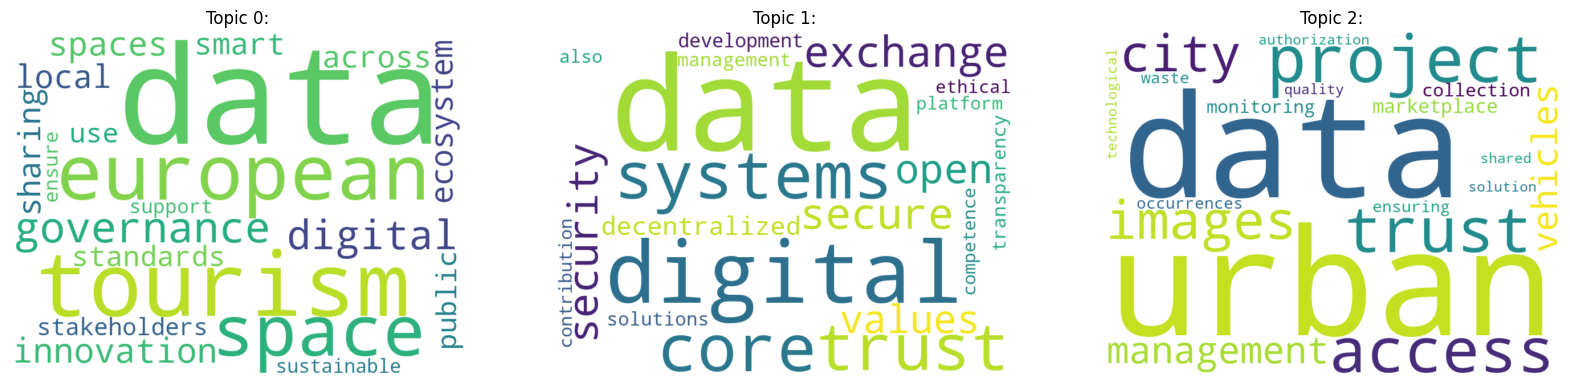

In [11]:
# --- Word Clouds for each LDA Topic ---
# To visualize the topics, we generate a word cloud for each one, showing the most
# important keywords.
topics_words = [(new_id[old], lda_best.show_topic(old, topn=20)) for old in order]
fig, axes = plt.subplots(1, best_k, figsize=(20, 6), sharey=True)

for i, (topic_id, topic) in enumerate(topics_words):
    topic_dict = {word: prob for word, prob in topic}
    wc = WordCloud(width=800, height=600, background_color="white", collocations=False)
    wc.generate_from_frequencies(topic_dict)
    axes[i].imshow(wc, interpolation='bilinear')
    axes[i].set_title(f"Topic {topic_id}:")
    axes[i].axis("off")
plt.show()

**LDA vs. BERTopic: Key Differences**

-   **LDA** is a "bag-of-words" model that finds topics by identifying words that frequently co-occur, ignoring context.
-   **BERTopic** is more advanced. It uses transformer models to understand the *meaning* of words in their context.

**How BERTopic Works & How it Uses TF-IDF:**
1.  **Embeddings**: It converts documents into numerical vectors (embeddings) that capture their semantic meaning.
2.  **Clustering**: It then clusters these vectors, **automatically determining the number of topics**.
3.  **Topic Words**: This is where it uses a TF-IDF variant. To find the most representative words for a topic, it uses **c-TF-IDF (class-based TF-IDF)**. It treats all documents in a cluster as a single large document and applies TF-IDF to identify which words are most important to *that specific cluster* compared to all other clusters.

This connection makes our initial TF-IDF analysis even more relevant, as the same core idea of term importance is adapted by BERTopic for a more powerful, context-aware result.

In [12]:
# --- Step 4: BERTopic Model ---
# We work on the original documents, passing our custom stopwords directly to the vectorizer.

vectorizer = CountVectorizer(stop_words=list(stop_words) + list(custom_stops))

topic_model = BERTopic(
    vectorizer_model=vectorizer,
    umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=42),
    hdbscan_model=HDBSCAN(min_cluster_size=2, metric='euclidean', cluster_selection_method='eom', prediction_data=True),
    language="english",
    calculate_probabilities=True,
    verbose=True
)

topics, probs = topic_model.fit_transform(docs)

# --- BERTopic Results Table ---
# - Topic: The ID. Topic -1 contains "outlier" documents that don't fit any cluster.
# - Count: Number of documents in the topic.
# - Name: Auto-generated name from the top keywords.
# - Representation: The full list of keywords.
# - Representative_Docs: An example document from the cluster

topic_info = topic_model.get_document_info(docs)
print("\nBERTopic Document Info for Tourism:")
topic_info

# topic_info = topic_model.get_topic_info()
# print("\nTopic Info:")
# topic_info

2026-10-20 18:18:22,138 - BERTopic - Embedding - Transforming documents to embeddings.


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

2026-10-20 18:18:37,383 - BERTopic - Embedding - Completed ✓
2026-10-20 18:18:37,388 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-20 18:18:41,799 - BERTopic - Dimensionality - Completed ✓
2026-10-20 18:18:41,799 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-20 18:18:41,820 - BERTopic - Cluster - Completed ✓
2026-10-20 18:18:41,828 - BERTopic - Representation - Extracting topics from clusters using representation models.
2026-10-20 18:18:41,851 - BERTopic - Representation - Completed ✓



BERTopic Document Info for Tourism:


,Document,Topic,Name,Representation,Representative_Docs,Top_n_words,Probability,Representative_document
0,Data is the driving force behind innovation an...,0,0_data_space_governance_urban,"[data, space, governance, urban, european, loc...",[Data is the driving force behind innovation a...,data - space - governance - urban - european -...,1.000000,True
1,datahub.tirol as the hub of the data economy. ...,0,0_data_space_governance_urban,"[data, space, governance, urban, european, loc...",[Data is the driving force behind innovation a...,data - space - governance - urban - european -...,1.000000,True
2,The European Tourism Data Space is one of the ...,1,1_data_tourism_european_innovation,"[data, tourism, european, innovation, space, d...","[EONA‑X is a European, non‑profit data‑sharing...",data - tourism - european - innovation - space...,0.605033,True
3,DEPLOYTOUR is a three-year project co-funded b...,1,1_data_tourism_european_innovation,"[data, tourism, european, innovation, space, d...","[EONA‑X is a European, non‑profit data‑sharing...",data - tourism - european - innovation - space...,1.000000,True
4,"EONA‑X is a European, non‑profit data‑sharing ...",1,1_data_tourism_european_innovation,"[data, tourism, european, innovation, space, d...","[EONA‑X is a European, non‑profit data‑sharing...",data - tourism - european - innovation - space...,1.000000,True
5,The European Data Space for Smart and Sustaina...,0,0_data_space_governance_urban,"[data, space, governance, urban, european, loc...",[Data is the driving force behind innovation a...,data - space - governance - urban - european -...,0.568188,True
6,cities worldwide complex products compete popu...,0,0_data_space_governance_urban,"[data, space, governance, urban, european, loc...",[Data is the driving force behind innovation a...,data - space - governance - urban - european -...,0.515304,False
7,TOURiLab is a pioneering initiative that seeks...,1,1_data_tourism_european_innovation,"[data, tourism, european, innovation, space, d...","[EONA‑X is a European, non‑profit data‑sharing...",data - tourism - european - innovation - space...,0.614606,False
8,Truzzt offers a cloud-based infrastructure des...,-1,-1_data_digital_core_decentralized,"[data, digital, core, decentralized, competenc...",[Why the UiTwisselingsplatform? During the rec...,data - digital - core - decentralized - compet...,0.165360,True
9,Why the UiTwisselingsplatform? During the rece...,-1,-1_data_digital_core_decentralized,"[data, digital, core, decentralized, competenc...",[Why the UiTwisselingsplatform? During the rec...,data - digital - core - decentralized - compet...,0.158626,True



Top words for each BERTopic in Tourism:
Topic 0: data (0.101), space (0.040), governance (0.033), urban (0.028), european (0.028), local (0.027), project (0.024), tidycity (0.024), smart (0.024), cities (0.023)
Topic 1: data (0.103), tourism (0.090), european (0.051), innovation (0.034), space (0.033), digital (0.030), eu (0.027), across (0.026), spaces (0.026), stakeholders (0.024)


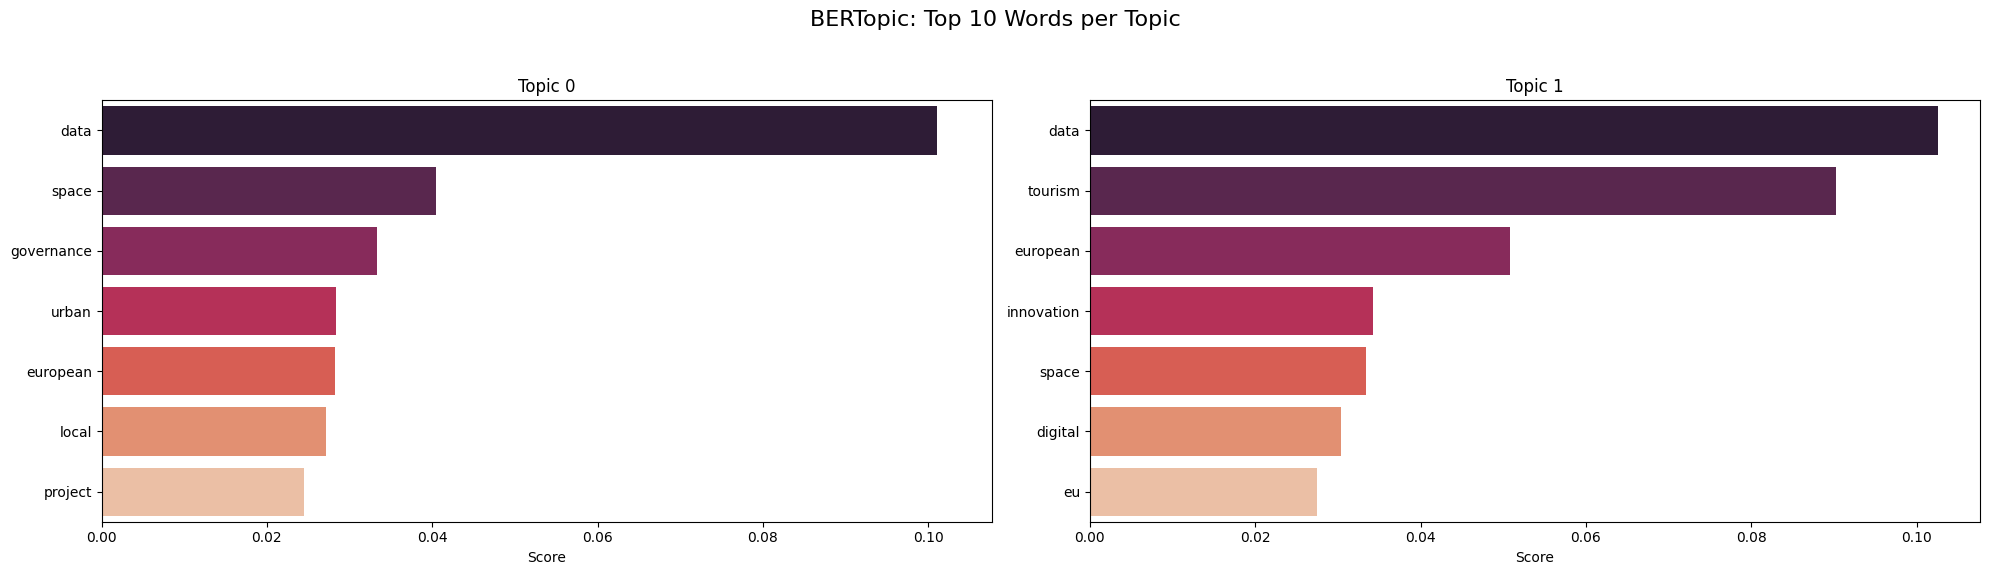

In [13]:
# --- BERTopic Topic Analysis and Visualization ---

# --- Text-based Topic Representation (similar to LDA) ---
# Here we inspect the top words and their c-TF-IDF scores for each topic.
print("\nTop words for each BERTopic in Tourism:")
for topic_id in sorted(topic_model.get_topics().keys()):
    if topic_id == -1: continue
    topic_words = topic_model.get_topic(topic_id)
    words_with_scores = ", ".join([f"{word} ({score:.3f})" for word, score in topic_words])
    print(f"Topic {topic_id}: {words_with_scores}")

# --- Top Words Bar Charts for BERTopic ---
# 1. Get the top 5 topics (excluding outlier Topic -1)
topic_ids = [t for t in topic_model.get_topics().keys() if t != -1][:5]

# 2. Setup Plot
fig, axes = plt.subplots(1, len(topic_ids), figsize=(20, 6), sharex=True)
fig.suptitle('BERTopic: Top 10 Words per Topic', fontsize=16)

for i, topic_id in enumerate(topic_ids):
    # 3. Get words/scores for this specific topic
    topic_data = topic_model.get_topic(topic_id)[:7]
    df_topic = pd.DataFrame(topic_data, columns=['Word', 'Score'])
    
    # 4. Plot
    sns.barplot(x='Score', y='Word', data=df_topic, ax=axes[i], palette='rocket')
    axes[i].set_title(f'Topic {topic_id}')
    axes[i].set_ylabel('')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

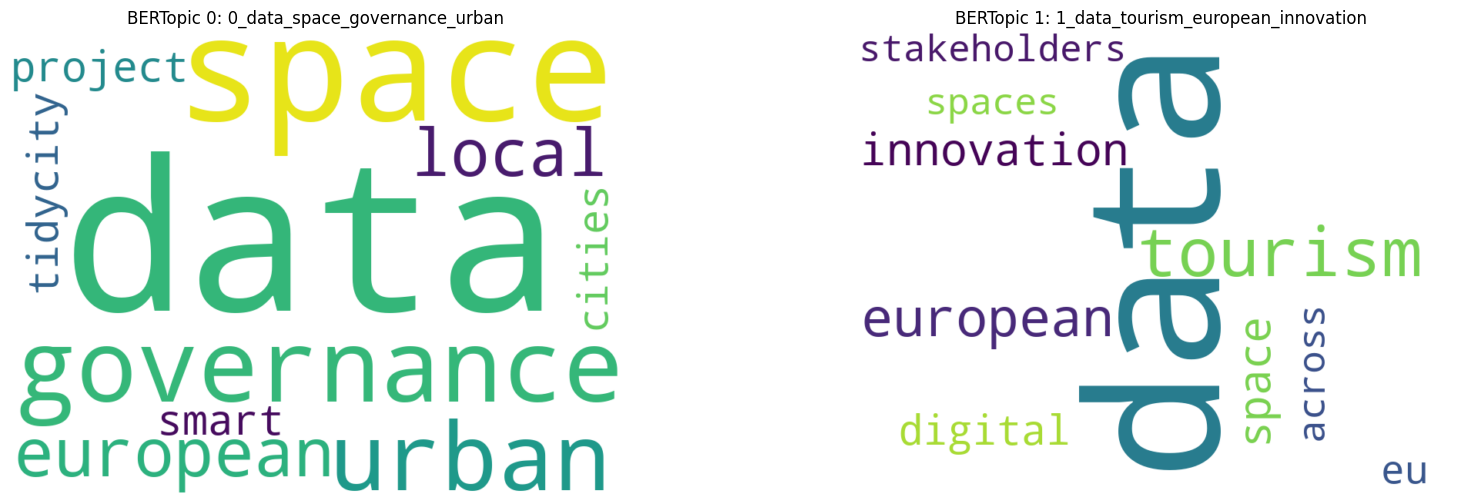

In [14]:
# --- Word Clouds for each BERTopic ---
# Filter out the outlier topic (-1) before plotting.
# This visualization helps in interpreting the themes of the discovered topics.
fig, axes = plt.subplots(1, len(set(topics) - {-1}), figsize=(20, 6), sharey=True)

for i, topic_id in enumerate(sorted(set(topics) - {-1})):
    topic_dict = dict(topic_model.get_topic(topic_id))
    wc = WordCloud(width=800, height=600, background_color="white", collocations=False)
    wc.generate_from_frequencies(topic_dict)
    axes[i].imshow(wc, interpolation='bilinear')
    axes[i].set_title(f"BERTopic {topic_id}: {topic_model.get_topic_info(topic_id)['Name'].iloc[0]} ")
    axes[i].axis("off")

plt.show()